In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patheffects as path_effects
import sunpy 
import sunpy.map
from sunpy.coordinates import propagate_with_solar_surface
import astropy
from astropy.io import fits, ascii
from astropy.visualization import ImageNormalize, AsinhStretch
import astropy.units as u
from sun_blinker import ImageBlinker, SunBlinker
import dkist
from fancy_colorbar import plot_colorbar
from sunkit_image import coalignment
from ndcube import NDCube
from astropy.wcs import WCS
import h5py 
import dask.array as da
from astropy.time import Time
from IPython.display import HTML, display

        Use pytest instead. [astropy.tests.runner]
        Use pytest instead. [astropy.utils.decorators]
        Use pytest instead. [astropy.tests.runner]
        Use pytest instead. [astropy.utils.decorators]


In [3]:
sotsp_blos_map = sunpy.map.Map("../../data/pid_1_123_aux/SOTSP/sotsp_blos_warp_to_hmi.fits")

In [4]:
file_Hbeta_pr = h5py.File("/cluster/home/zhuyin/Solar/DKIST_SolO_Fibril/data/pid_1_123_aux/plot_ready/Hbeta_BJOLO_pr.hdf5")
Hbeta_pr_set = file_Hbeta_pr["vbi_img"]
Hbeta_pr_da = da.from_array(Hbeta_pr_set, chunks=(1, 4096 - 128*2, 4096 - 128*2))
Hbeta_date_obs = Time(ascii.read("/cluster/home/zhuyin/Solar/DKIST_SolO_Fibril/data/pid_1_123_aux/plot_ready/Hbeta_BJOLO_date_avg.txt")["DATE-AVG"])

file_Gband_pr = h5py.File("/cluster/home/zhuyin/Solar/DKIST_SolO_Fibril/data/pid_1_123_aux/plot_ready/Gband_AEZDV_pr.hdf5")
Gband_pr_set = file_Gband_pr["vbi_img"]
Gband_pr_da = da.from_array(Gband_pr_set, chunks=(1, 4096 - 128*2, 4096 - 128*2))
Gband_date_obs = Time(ascii.read("/cluster/home/zhuyin/Solar/DKIST_SolO_Fibril/data/pid_1_123_aux/plot_ready/Gband_AEZDV_date_avg.txt")["DATE-AVG"])

dkist_vbi_target_header = fits.getheader("/cluster/home/zhuyin/Solar/DKIST_SolO_Fibril/data/pid_1_123_aux/plot_ready/dkist_target_wcs_header_before_crop.fits",
                                        ignore_missing_simple=True)

dkist_vbi_target_data = np.zeros((4096,4096))

dkist_vbi_target_cube = NDCube(dkist_vbi_target_data,WCS(dkist_vbi_target_header, naxis=2))
dkist_vbi_target_cube_crop = dkist_vbi_target_cube[128:-128,128:-128]
dkist_vbi_target_cube_crop_rebin = dkist_vbi_target_cube_crop.rebin((16,16))
dkist_vbi_target_cube_crop_rebin_4 = dkist_vbi_target_cube_crop.rebin((4,4))

Set MJD-BEG to 59876.791095 from DATE-BEG.
Set MJD-AVG to 59876.791095 from DATE-AVG.
Set MJD-END to 59876.791095 from DATE-END'. [astropy.wcs.wcs]
Set OBSGEO-B to    20.706700 from OBSGEO-[XYZ].
Set OBSGEO-H to     3063.997 from OBSGEO-[XYZ]'. [astropy.wcs.wcs]


In [6]:
Gband_syn_raster = np.load("../../data/pid_1_123_aux/VBI_syn_raster/Gband_syn_raster.npy")
Hbeta_syn_raster = np.load("../../data/pid_1_123_aux/VBI_syn_raster/Hbeta_syn_raster.npy")

In [8]:
def repro_higherlevel_wcs(map, target_wcs, algorithm="adaptive"):
    cube = NDCube(map.data, map.wcs)
    cube_repro = cube.reproject_to(target_wcs, algorithm=algorithm)

    return cube_repro

In [9]:
with propagate_with_solar_surface():
    sotsp_blos_map_to_vbi = repro_higherlevel_wcs(sotsp_blos_map, dkist_vbi_target_cube_crop_rebin_4.wcs, algorithm="exact")

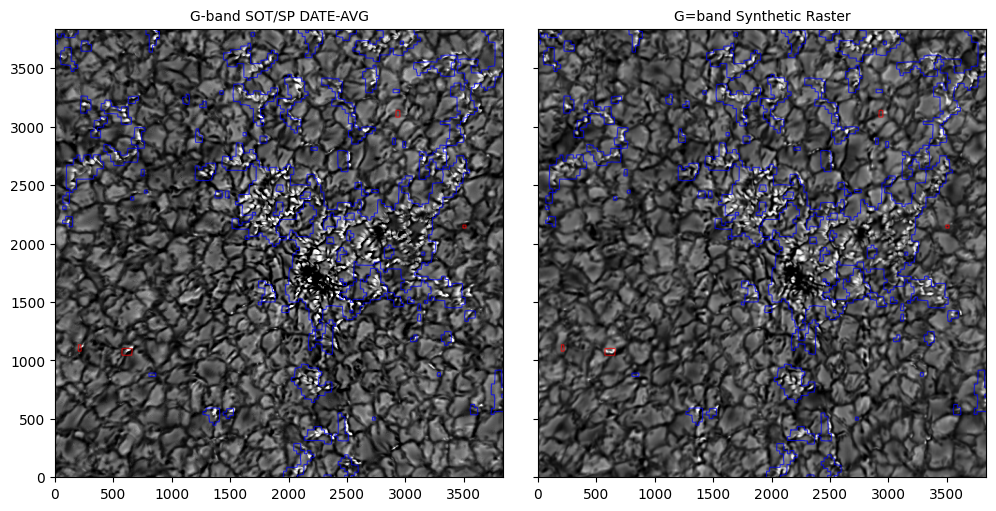

In [18]:
fig, (ax1,ax2) = plt.subplots(1,2,figsize=(10,5), layout="constrained", 
    sharex=True, sharey=True)

im1 = ax1.imshow(Gband_pr_da[100,:,:],
    cmap="Greys_r",
    vmin=0,
    vmax=1.5,
    origin="lower",
    interpolation="nearest",)

im2 = ax2.imshow(
    Gband_syn_raster,
    cmap="Greys_r",
    vmin=0,
    vmax=1.5,
    origin="lower",
)

ax1.set_title("G-band SOT/SP DATE-AVG", fontsize=10)
ax2.set_title("G-band Synthetic Raster", fontsize=10)

for ax_ in (ax1,ax2):
    ax_.contour(sotsp_blos_map_to_vbi.data, levels=[-100,100],
                colors=["red", "blue"], linewidths=0.8,
                extent=im1.get_extent(), origin="lower", alpha=0.7)

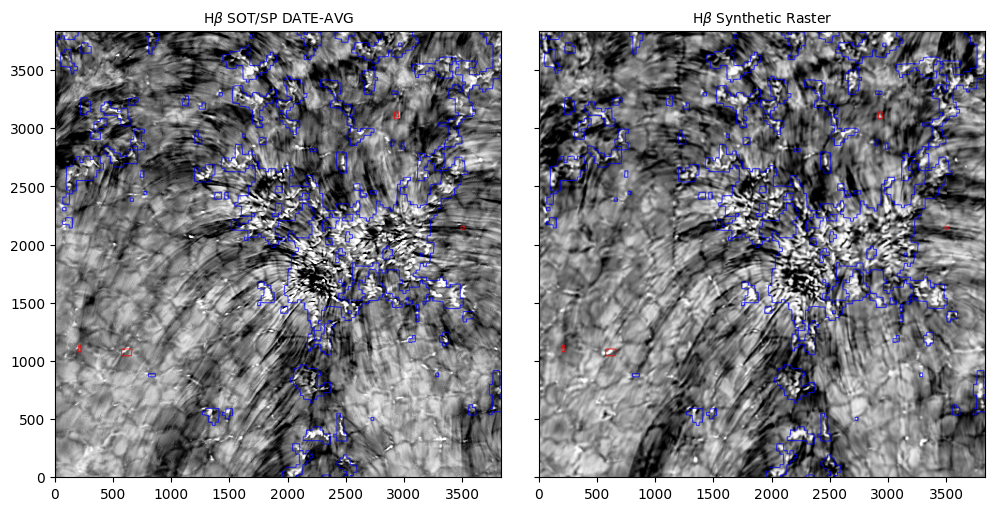

In [20]:
fig, (ax1,ax2) = plt.subplots(1,2,figsize=(10,5), layout="constrained", 
    sharex=True, sharey=True)

im1 = ax1.imshow(Hbeta_pr_da[99,:,:],
    cmap="Greys_r",
    vmin=0,
    vmax=1.2,
    origin="lower",
    interpolation="nearest",)

im2 = ax2.imshow(
    Hbeta_syn_raster,
    cmap="Greys_r",
    vmin=0,
    vmax=1.2,
    origin="lower",
)

ax1.set_title(r"H$\beta$ SOT/SP DATE-AVG", fontsize=10)
ax2.set_title(r"H$\beta$ Synthetic Raster", fontsize=10)

for ax_ in (ax1,ax2):
    ax_.contour(sotsp_blos_map_to_vbi.data, levels=[-100,100],
                colors=["red", "blue"], linewidths=0.8,
                extent=im1.get_extent(), origin="lower", alpha=0.7)